# Hwang et al. 2022 — PDAC
## 02 · Manifold & trajectory
Fit a scFates principal **curve** (the manifold is a single continuous axis, not a Y — established in 03 from the module geography: no Gast/pSom co-expression hub). Build the house linear layout as a **rigid rotation** of the integrated UMAP (never a fresh re-embedding, which would risk a fold), root at the developmental origin (Crest is late/terminal, so root = the Crest-low pole), infer pseudotime, and verify the curve is fold-free on an **independent** geometry.

In [1]:
import os, sys, glob, warnings, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import scanpy as sc, scFates as scf
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
sc.settings.verbosity = 0
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4)); pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('loaded processed.h5ad:', adata.shape, '| compartments:', adata.obs['celltype'].value_counts().to_dict())

loaded processed.h5ad: (64006, 19444) | compartments: {'Basal-like': 54795, 'Classical-like': 9211}


**Score developmental modules + graph-smooth** (for root derivation and topology; 03 re-scores canonically for the signature figures). Smoothing averages scores over each cell's kNN — geography, not per-cell noise.

In [5]:
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=l, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0]); A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,l in enumerate(['Gast','pSom','Crest']): adata.obs[l+'_sm'] = S[:,j]
print('raw module means:', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())

raw module means: {'Gast': -0.0044, 'pSom': -0.0019, 'Crest': 0.0025}


**House linear layout — rigid rotation of the integrated UMAP.** We rotate the existing embedding onto its principal axis (distances preserved). This is *not* a fresh UMAP: re-embedding an elongated compartment is exactly what folds a strip into a U (Kürten eval fork 4), so we avoid it.

In [7]:
xy = adata.obsm['X_umap']; c0 = xy - xy.mean(0)
aspect = c0.std(0).max()/c0.std(0).min()
_,_,vt = np.linalg.svd(c0, full_matrices=False); th = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-th),-np.sin(-th)],[np.sin(-th),np.cos(-th)]])
adata.obsm['X_umap_lin'] = c0 @ Rm.T
print(f'manifold aspect (max/min std) = {aspect:.2f}; house layout = rigid rotation {np.degrees(th):+.1f}deg')

manifold aspect (max/min std) = 1.13; house layout = rigid rotation +147.2deg


**Fit the principal curve** (ElPiGraph, 20 nodes) on the integrated UMAP, then diagnose topology from the graph geometry: number of tips/forks and a fold self-approach ratio (min distance between graph-distant nodes / median edge length; >1 = no fold-back).

In [9]:
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(adata, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
B = np.asarray(adata.uns['graph']['B']); F = adata.uns['graph']['F'].T
G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
ii,jj = np.where(np.triu(B>0)); med = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
dmin = np.inf
for a in range(F.shape[0]):
    for b in range(a+1, F.shape[0]):
        if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
print(f'curve: {tips} tips, {forks} forks | fold self-approach ratio = {dmin/med:.2f} (>1 = fold-free)')
assert forks == 0, 'curve unexpectedly branched'

curve: 2 tips, 0 forks | fold self-approach ratio = 2.81 (>1 = fold-free)


**Root at the developmental origin.** Assign each tip its mean smoothed module scores over nearby nodes. The reliable developmental anchor is that **neural crest is terminal/late**: the terminus is the Crest-high tip, the root is the opposite (Crest-low, gastrulation/somitogenesis) pole.

In [11]:
tps = np.where((B>0).sum(0)==1)[0]; Rr = np.asarray(adata.obsm['X_R']); hard = Rr.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (adata.obs['Gast_sm'][m].mean(), adata.obs['pSom_sm'][m].mean(), adata.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
terminus = int(max(tps, key=lambda tp: info[tp][2]))       # Crest-high = terminal
root = int([t for t in tps if t != terminus][0])           # Crest-low origin
print(f'derived root = tip {root} (Crest-low origin); terminus = tip {terminus} (Crest-high)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(adata, root); scf.tl.pseudotime(adata, n_map=1, seed=SEED)
adata.uns['root_tip'] = root; adata.uns['terminus_tip'] = terminus

tip 0: Gast=-0.0037 pSom=-0.0032 Crest=+0.0053
tip 2: Gast=-0.0151 pSom=+0.0021 Crest=+0.0028
derived root = tip 2 (Crest-low origin); terminus = tip 0 (Crest-high)


**Developmental order along pseudotime.** Somitogenesis/gastrulation early -> neural crest late confirms the root; orient the house layout so the origin sits on the left.

In [13]:
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('pseudotime gradients (Spearman rho on smoothed scores):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, adata.obs[s]); print(f'  {s}: rho={rho:+.3f} p={p:.1e}')
for m,lab in [('pSom_sm','Somitogenesis'),('Gast_sm','Gastrulation'),('Crest_sm','Neural-crest')]:
    hi = adata.obs[m] >= adata.obs[m].quantile(0.9)
    print(f'{lab}-high decile mean pseudotime = {tn[hi.values].mean():.2f}')
r = float(np.corrcoef(adata.obsm['X_umap_lin'][:,0], t)[0,1])
if r < 0: adata.obsm['X_umap_lin'][:,0] = -adata.obsm['X_umap_lin'][:,0]; r = -r
print(f'corr(X_umap_lin x, pseudotime) = {r:+.2f} (origin on the left)')

pseudotime gradients (Spearman rho on smoothed scores):
  Gast_sm: rho=+0.294 p=0.0e+00
  pSom_sm: rho=-0.337 p=0.0e+00
  Crest_sm: rho=+0.335 p=0.0e+00
Somitogenesis-high decile mean pseudotime = 0.16
Gastrulation-high decile mean pseudotime = 0.59
Neural-crest-high decile mean pseudotime = 0.63
corr(X_umap_lin x, pseudotime) = +0.96 (origin on the left)


**Independent fold check.** The self-approach ratio above was read off the same UMAP the curve was fit on. Here we verify continuity on an **independent** geometry — a diffusion map on the Harmony-PCA representation the UMAP-fit curve never used — via (i) pseudotime vs the top diffusion component and (ii) a monotone, non-self-approaching centroid path through Harmony-PCA space.

In [15]:
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.diffmap(adata, n_comps=10)
dc = adata.obsm['X_diffmap']
best = max(range(1,6), key=lambda i: abs(spearmanr(t, dc[:,i]).correlation)); rho = spearmanr(t, dc[:,best]).correlation
print(f'pseudotime vs diffusion DC{best} (independent Harmony-PCA geometry): rho = {rho:+.3f}')
rep = adata.obsm['X_pca_harmony'][:,:20]; bins = pd.qcut(tn, 20, labels=False, duplicates='drop')
cent = np.array([rep[bins==b].mean(0) for b in range(bins.max()+1)])
step = np.sqrt(((cent[1:]-cent[:-1])**2).sum(1))
dmin2 = min(np.sqrt(((cent[a]-cent[b])**2).sum()) for a in range(len(cent)) for b in range(a+3,len(cent)))
print(f'Harmony-PCA centroid path: median step={np.median(step):.3f}, min non-adjacent gap={dmin2:.3f}, ratio={dmin2/np.median(step):.2f} (>1 = no fold-back)')
print('-> curve is continuous and fold-free in an embedding it was not fit on.')

pseudotime vs diffusion DC2 (independent Harmony-PCA geometry): rho = -0.731
Harmony-PCA centroid path: median step=0.653, min non-adjacent gap=1.485, ratio=2.27 (>1 = no fold-back)
-> curve is continuous and fold-free in an embedding it was not fit on.


In [16]:
adata.uns['epg'] = {'NodePositions': np.asarray(adata.uns['epg']['NodePositions'])}
adata.write(os.path.join(pth_out, 'manifold.h5ad'))
print('saved manifold.h5ad', adata.shape, '| root tip', adata.uns['root_tip'], 'terminus tip', adata.uns['terminus_tip'])

saved manifold.h5ad (64006, 19444) | root tip 2 terminus tip 0


**Figure — `manifold.pdf`.** House `(3.5,1.5)` strip on the linear layout, coloured by pseudotime (origin left -> terminus right).

saved manifold.pdf


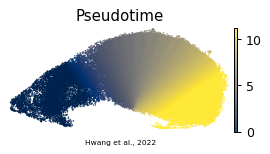

In [18]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']; xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=6, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Hwang et al., 2022', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.pdf')